In [ ]:
import os
from imutils import paths
import matplotlib.pyplot as plt
import cv2
import numpy as np
import tensorflow as tf
import tensorflow.keras as k
import pandas as pd
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!unzip -q /content/drive/MyDrive/seg.zip -d /content/seg_data

In [ ]:
# fatch data from seg_train and test
path_train = './seg_data/seg/seg_train'
path_test = './seg_data/seg/seg_test'
# color in 0-255
# the model input 0-255 and convert to 0-1
batch_size = 64
image_size = (150,150)

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    path_train ,
    shuffle = True ,
    validation_split=0.2,
    subset="training",
    seed = 123,
    batch_size = batch_size ,
    image_size = image_size
)
# to valid trinnig on run
val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    path_train ,
    shuffle = True ,
    validation_split=0.2,
    subset="validation",
    seed=123,
    batch_size = batch_size ,
    image_size = image_size
)

test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    path_test ,
    shuffle = False ,
    batch_size = batch_size ,
    image_size = image_size
)
class_names = train_ds.class_names
print("الفئات الموجودة:", class_names)
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.
الفئات الموجودة: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


In [ ]:
for images, labels in train_ds.take(1):
    print("\n--- Batch Information ---")
    print(f"Image Batch Shape (Batch, Height, Width, Channels): {images.shape}")
    print(f"Labels Batch Shape: {labels.shape}")
    print(f"Min Pixel Value: {tf.reduce_min(images).numpy():.2f}")
    print(f"Max Pixel Value: {tf.reduce_max(images).numpy():.2f}")
    print(f"Sample Encoded Labels in Batch: {labels[:10].numpy()} , and length {len(labels)}")



--- Batch Information ---
Image Batch Shape (Batch, Height, Width, Channels): (64, 150, 150, 3)
Labels Batch Shape: (64,)
Min Pixel Value: 0.00
Max Pixel Value: 255.00
Sample Encoded Labels in Batch: [1 5 1 3 5 2 3 1 1 5] , and length 64


=== Class Distribution Table ===
Class Name  Train Images  Test Images  Total Images
  mountain          2512          525          3037
       sea          2274          510          2784
   glacier          2404          553          2957
    forest          2271          474          2745
 buildings          2191          437          2628
    street          2382          501          2883


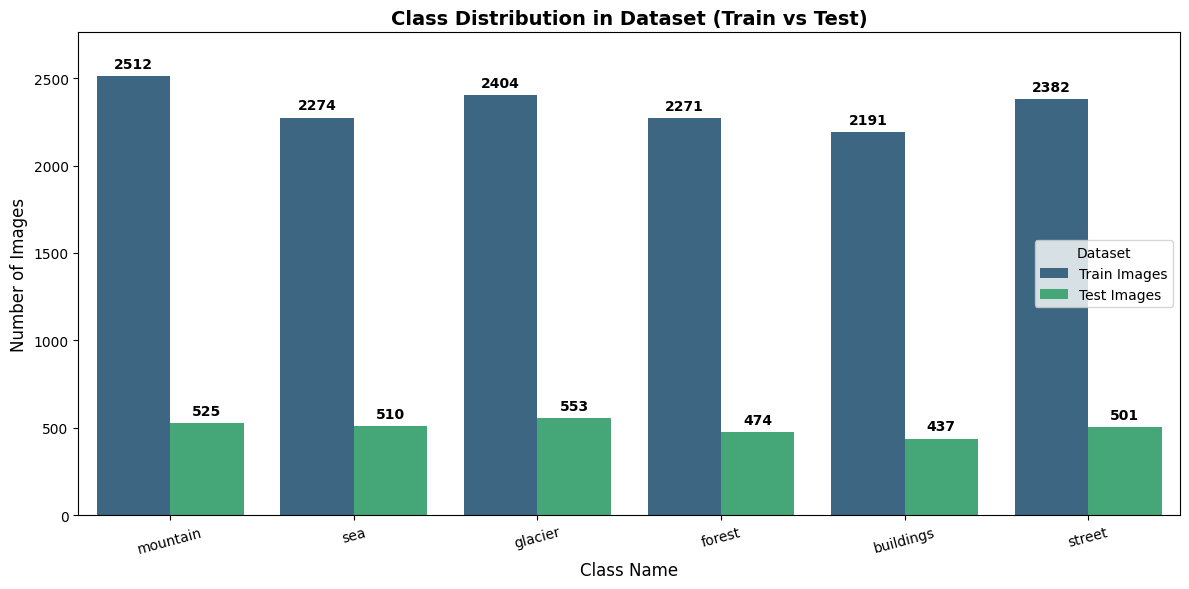

In [ ]:
TRAIN_DIR = './seg_data/seg/seg_train'
TEST_DIR = './seg_data/seg/seg_test'

# 1. إحصاء عدد الصور في كل فئة لبيانات التدريب والاختبار
classes = os.listdir(TRAIN_DIR)
train_counts = {}
test_counts = {}

for cls in classes:
    train_path = os.path.join(TRAIN_DIR, cls)
    test_path = os.path.join(TEST_DIR, cls)

    if os.path.isdir(train_path):
        train_counts[cls] = len(os.listdir(train_path))
    if os.path.isdir(test_path):
        test_counts[cls] = len(os.listdir(test_path))

# 2. إنشاء جدول الإحصائيات (Pandas DataFrame)
df_counts = pd.DataFrame({
    'Class Name': list(train_counts.keys()),
    'Train Images': list(train_counts.values()),
    'Test Images': [test_counts.get(cls, 0) for cls in train_counts.keys()]
})

df_counts['Total Images'] = df_counts['Train Images'] + df_counts['Test Images']
print("=== Class Distribution Table ===")
print(df_counts.to_string(index=False))

df_melted = df_counts.melt(
    id_vars=['Class Name'],
    value_vars=['Train Images', 'Test Images'],
    var_name='Dataset Type',
    value_name='Number of Images'
)

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x='Class Name',
    y='Number of Images',
    hue='Dataset Type',
    data=df_melted,
    palette='viridis'
)

plt.title('Class Distribution in Dataset (Train vs Test)', fontsize=14, fontweight='bold')
plt.xlabel('Class Name', fontsize=12)
plt.ylabel('Number of Images', fontsize=12)
plt.xticks(rotation=15)
plt.legend(title='Dataset')

for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(
            f'{int(height)}',
            (p.get_x() + p.get_width() / 2., height + 30),
            ha='center',
            va='bottom',
            fontsize=10,
            fontweight='bold',
            color='black'
        )

# رفع حد المحور Y لضمان عدم خروج الأرقام عن الإطار
plt.ylim(0, max(df_counts['Train Images']) + 250)

plt.tight_layout()
plt.show()


# trint model


In [ ]:

def build_4layer_model():
  model = k.Sequential([
      # rotite and flip imge random
      k.layers.RandomFlip("horizontal", input_shape=(None, None , 3)),
      k.layers.RandomRotation(0.1),
      # convert from 0-255 to 0-1
      k.layers.Rescaling(1./255),
      # one
      # 32 filter conv (3x3) -> actuv (Rule) -> maxpooling (2x2)
      k.layers.Conv2D(32 , 3 , padding='same' ,activation='relu' ),
      k.layers.MaxPool2D(pool_size=(2,2) , strides=(2,2)),

      # tow
      # 64 filter conv (3x3) -> actuv (Rule) -> maxpooling (2x2)
      k.layers.Conv2D(64 , 3 , padding='same' ,activation='relu' ),
      k.layers.MaxPool2D(pool_size=(2,2) , strides=(2,2)),

      # three
      # 128 filter conv (3x3) -> actuv (Rule) -> maxpooling (2x2)
      k.layers.Conv2D(128 , 3 , padding='same' ,activation='relu' ),
      k.layers.MaxPool2D(pool_size=(2,2) , strides=(2,2)),

      # four
      # 256 filter conv (3x3) -> actuv (Rule) -> maxpooling (2x2)
      k.layers.Conv2D(256 , 3 , padding='same' ,activation='relu' ),
      k.layers.MaxPool2D(pool_size=(2,2) , strides=(2,2)),

      # k.layers.Flatten(),

      k.layers.Conv2D(128 , 9 , padding='valid' ,activation='relu' ),

      k.layers.Conv2D(6, kernel_size=(1, 1), activation='softmax'),

      k.layers.Reshape((6,))
      # k.layers.Dense(128 , activation='relu'),
      # k.layers.Dropout(0.4),
      # k.layers.Dense(6 , activation='softmax')

  ])
  model.summary()

  model.compile(
      optimizer=k.optimizers.Adam(learning_rate=0.001),
      loss='sparse_categorical_crossentropy',
      metrics=['accuracy']
              )
  return model


model_4 = build_4layer_model()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, None, None, 3)  │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, None, None, 32) │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, None, None, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, None, None, 64) │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, None, None,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, None, None,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, None, None,     │     2,654,336 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, None, None, 6)  │           774 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 6)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,043,526 (11.61 MB)

 Trainable params: 3,043,526 (11.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history_4 = model_4.fit(train_ds , validation_data=val_ds , epochs=10)

# model_4.save('model_4layer.keras')

# np.save('history_4layer.npy', history_4.history)

Epoch 1/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 28s 73ms/step - accuracy: 0.5631 - loss: 1.1050 - val_accuracy: 0.6928 - val_loss: 0.8249
Epoch 2/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 12s 66ms/step - accuracy: 0.6925 - loss: 0.8271 - val_accuracy: 0.7331 - val_loss: 0.7578
Epoch 3/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 12s 70ms/step - accuracy: 0.7495 - loss: 0.6880 - val_accuracy: 0.7527 - val_loss: 0.6873
Epoch 4/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 12s 71ms/step - accuracy: 0.7858 - loss: 0.6086 - val_accuracy: 0.7434 - val_loss: 0.7567
Epoch 5/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 13s 75ms/step - accuracy: 0.7909 - loss: 0.5763 - val_accuracy: 0.8036 - val_loss: 0.5508
Epoch 6/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 12s 67ms/step - accuracy: 0.8035 - loss: 0.5367 - val_accuracy: 0.8250 - val_loss: 0.5161
Epoch 7/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 65ms/step - accuracy: 0.8199 - loss: 0.5002 - val_accuracy: 0.8329 - val_loss: 0.4685
Epoch 8/10
176/176 ━━━━━━━━━━━━━━━━━━━━ 11s 65ms/step - accuracy: 0.8350 - loss: 0.4618 - 

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 261ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 322ms/step
🎯 توقع الموديل النهائي للصورة هو: buildings

📊 نسب ثقة الموديل لكل التصنيفات:
- buildings: 99.97%
- forest: 1.03%
- glacier: 1.30%
- mountain: 3.65%
- sea: 19.15%
- street: 37.17%


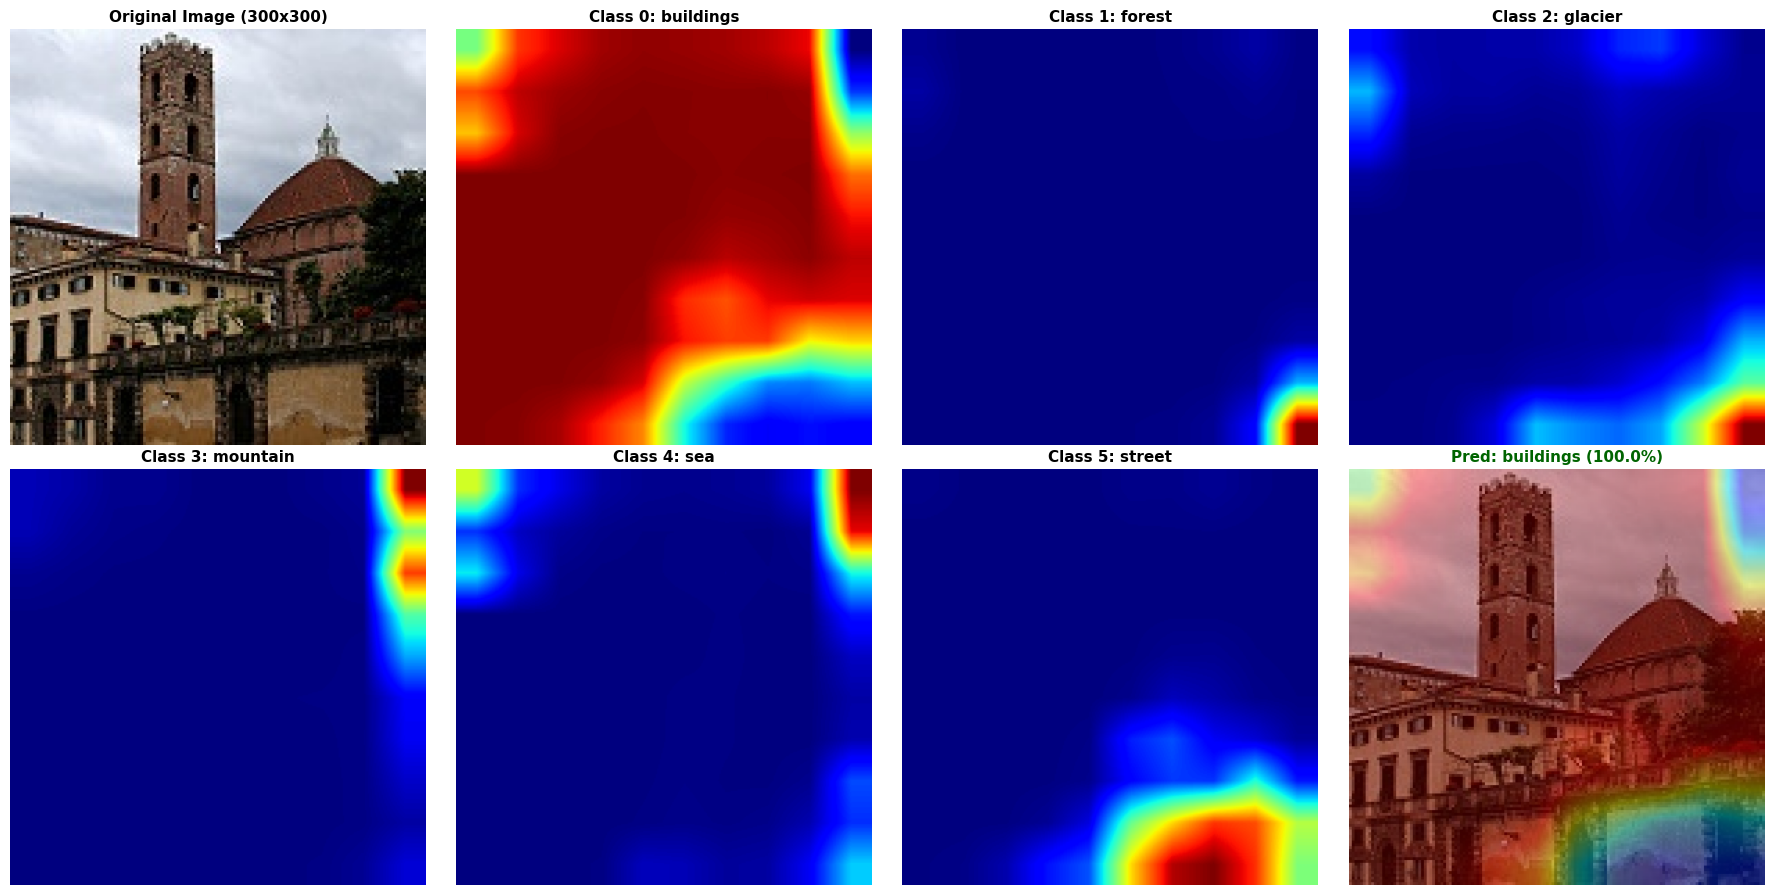

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
heatmap_model = tf.keras.Model(
    inputs= model_4.inputs,
    outputs= model_4.layers[-2].output
)

# 2. تحميل وتحضير صورة كبيرة (300x300)
img_path = './seg_data/seg/seg_test/buildings/20061.jpg'

# تحميل الصورة بحجم 300x300
img = tf.keras.utils.load_img(img_path, target_size=(300, 300))
img_array = tf.keras.utils.img_to_array(img)

# إضافة بعد الـ Batch لتصبح الأبعاد: (1, 300, 300, 3)
input_tensor = np.expand_dims(img_array, axis=0)

# 3. التنبؤ وتوليد الخريطة الحرارية
# الناتج سيكون مصفوفة بأبعاد مثل (1, 19, 19, 6)
heatmaps = heatmap_model.predict(input_tensor)
# حساب متوسط أفضل 20% من البكسلات فقط في كل خريطة
top_k_pixels = int(0.2 * heatmaps[0].shape[0] * heatmaps[0].shape[1])
class_scores = [
    np.sort(heatmaps[0, :, :, i].flatten())[-top_k_pixels:].mean()
    for i in range(6)
]
# 1. حساب متوسط الاحتمالية لكل كلاس عبر كامل الـ Heatmap
# class_scores = np.mean(heatmaps[0], axis=(0, 1))  # مصفوفة فيها 6 أرقام

# 2. تحديد الكلاس الفائز (صاحب أعلى متوسط)
predicted_class_id = np.argmax(class_scores)
predicted_class_name = class_names[predicted_class_id]

print(f"🎯 توقع الموديل النهائي للصورة هو: {predicted_class_name}\n")

# 3. طباعة نسبة كل كلاس بالترتيب
print("📊 نسب ثقة الموديل لكل التصنيفات:")
for i, score in enumerate(class_scores):
    print(f"- {class_names[i]}: {score * 100:.2f}%")

# تجهيز نافذة العرض (صورة أصلية + 6 خرائط حرارية + صورة دمج الكلاس الفائز)
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.ravel()

# 1. عرض الصورة الأصلية في أول خانة
original_img = img_array.astype(np.uint8)
axes[0].imshow(original_img)
axes[0].set_title("Original Image (300x300)", fontsize=11, fontweight='bold')
axes[0].axis('off')

# 2. عرض الخرائط الحرارية الـ 6 الصافية
for i in range(6):
    # استخراج خريطة الكلاس i
    heatmap = heatmaps[0, :, :, i]

    # تنظيف وتطبيع القيم (0 إلى 1)
    heatmap = np.maximum(heatmap, 0)
    if np.max(heatmap) != 0:
        heatmap /= np.max(heatmap)

    # تكبير الخريطة لأبعاد 300x300
    heatmap_resized = cv2.resize(heatmap, (300, 300))

    # عرض الخريطة الحرارية الصافية بألوان jet
    im = axes[i + 1].imshow(heatmap_resized, cmap='jet')

    # كتابة رقم الكلاس واسمه الحقيقي فوق كل خريطة
    axes[i + 1].set_title(f"Class {i}: {class_names[i]}", fontsize=11, fontweight='bold')
    axes[i + 1].axis('off')

# 3. الخانة الثامنة (axes[7]): دمج الصورة الأصلية مع الخريطة الحرارية للكلاس الفائز
winning_heatmap = heatmaps[0, :, :, predicted_class_id]
winning_heatmap = np.maximum(winning_heatmap, 0)
if np.max(winning_heatmap) != 0:
    winning_heatmap /= np.max(winning_heatmap)

# تكبير خريطة الكلاس الفائز وتلوينها
winning_heatmap_resized = cv2.resize(winning_heatmap, (300, 300))
winning_heatmap_colored = cv2.applyColorMap(np.uint8(255 * winning_heatmap_resized), cv2.COLORMAP_JET)
winning_heatmap_colored = cv2.cvtColor(winning_heatmap_colored, cv2.COLOR_BGR2RGB)

# دمج الخريطة الملونة مع الصورة الأصلية بنسبة شفافية (Overlay)
superimposed_img = cv2.addWeighted(original_img, 0.6, winning_heatmap_colored, 0.4, 0)

# عرض الصورة المدمجة في الخانة الثامنة
axes[7].imshow(superimposed_img)
axes[7].set_title(f"Pred: {predicted_class_name} ({class_scores[predicted_class_id]*100:.1f}%)",
                  fontsize=11, fontweight='bold', color='darkgreen')
axes[7].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
r = model_4.evaluate(test_ds)
print(f'model_4 accurcy is %{r[1]*100:.2f}')

model_4.save('model_4layer.keras')

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.8213 - loss: 0.5041
model_4 accurcy is %82.13


In [ ]:

def build_3layer_model():
  model = k.Sequential([
      # rotite and flip imge random
      k.layers.RandomFlip("horizontal", input_shape=(150, 150, 3)),
      k.layers.RandomRotation(0.1),

      k.layers.Rescaling(1./255),

      # one
      # 32 filter conv (3x3) -> actuv (Rule) -> maxpooling (2x2)
      k.layers.Conv2D(32 , 3 , padding='same' ,activation='relu' ),
      k.layers.MaxPool2D(pool_size=(2,2) , strides=(2,2)),

      # tow
      # 64 filter conv (3x3) -> actuv (Rule) -> maxpooling (2x2)
      k.layers.Conv2D(64 , 3 , padding='same' ,activation='relu' ),
      k.layers.MaxPool2D(pool_size=(2,2) , strides=(2,2)),


      # three
      # 128 filter conv (3x3) -> actuv (Rule) -> maxpooling (2x2)
      k.layers.Conv2D(128 , 3 , padding='same' ,activation='relu' ),
      k.layers.MaxPool2D(pool_size=(2,2) , strides=(2,2)),


      k.layers.Flatten(),

      k.layers.Dense(64 , activation='relu'),
      k.layers.Dropout(0.3),

      k.layers.Dense(6 , activation='softmax')

  ])
  model.summary()

  model.compile(
      optimizer=k.optimizers.Adam(learning_rate=0.001),
      loss='sparse_categorical_crossentropy',
      metrics=['accuracy']
  )


  return model
model_3 = build_3layer_model()


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_9 (RandomFlip)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_9               │ (None, 150, 150, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_12 (Rescaling)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_40 (Conv2D)              │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_40 (MaxPooling2D) │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_41 (Conv2D)              │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_41 (MaxPooling2D) │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_42 (Conv2D)              │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_42 (MaxPooling2D) │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_12 (Flatten)            │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 64)             │     2,654,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,747,910 (10.48 MB)

 Trainable params: 2,747,910 (10.48 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:


history_3 = model_3.fit(train_ds , validation_data=val_ds , epochs=10)


Epoch 1/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.5249 - loss: 1.2003 - val_accuracy: 0.6212 - val_loss: 0.9275
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 21s 30ms/step - accuracy: 0.6288 - loss: 0.9671 - val_accuracy: 0.6148 - val_loss: 1.0237
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 20s 29ms/step - accuracy: 0.6813 - loss: 0.8580 - val_accuracy: 0.7324 - val_loss: 0.6973
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.7075 - loss: 0.7913 - val_accuracy: 0.7680 - val_loss: 0.6508
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 22s 33ms/step - accuracy: 0.7382 - loss: 0.7198 - val_accuracy: 0.7976 - val_loss: 0.5811
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 19s 30ms/step - accuracy: 0.7525 - loss: 0.6798 - val_accuracy: 0.7983 - val_loss: 0.5390
Epoch 7/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 10s 30ms/step - accuracy: 0.7700 - loss: 0.6443 - val_accuracy: 0.8104 - val_loss: 0.5116
Epoch 8/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.7844 - loss: 0.6021 - 

In [ ]:

r = model_3.evaluate(test_ds)
print(f'model_3 accurcy is %{r[1]*100:.2f}')

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8123 - loss: 0.5500
model_3 accurcy is %81.23


In [ ]:

model_3.save('model_3layer.keras')

np.save('history_3layer.npy', history_3.history)

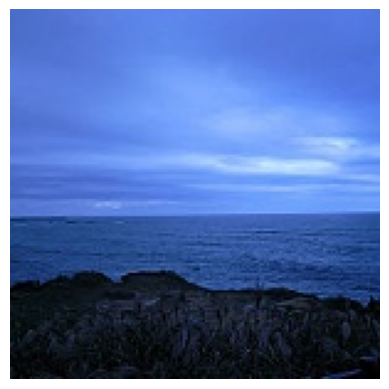

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step


('sea', np.float32(0.96943027))

In [ ]:
path ='./seg/seg_test/sea/20081.jpg'
def predict(path):

    imge = cv2.imread(path)
    imge = cv2.cvtColor(imge, cv2.COLOR_BGR2RGB)
    plt.imshow(imge)
    plt.axis('off')
    plt.show()
    imge = np.expand_dims(imge, axis=0)
    imge = tf.constant(imge)

    p = model.predict(imge)
    x = np.argmax(p[0])
    return class_names[x] , p.max()

predict(path)